# 02 · Acoustic feature extraction

**Goal:** convert each of the 1,440 clips into one row of numbers that a classifier can use.

For every clip we measure 15 kinds of acoustic descriptors on short overlapping frames (≈93 ms window, ≈23 ms hop), then summarise each descriptor over the clip with its mean and standard deviation. The result is a table with **190 features per clip**. The full list is in `docs/FEATURES.md`.

| Family | Count | What it captures |
|---|---|---|
| MFCC, Δ, ΔΔ | 120 | Timbre / vocal-tract shape and how fast it changes |
| Spectral shape (centroid, bandwidth, roll-off, flatness) | 8 | Brightness and noisiness of the voice |
| Spectral contrast | 14 | Peak-vs-valley energy in 7 frequency bands |
| Chroma | 24 | Energy in the 12 pitch classes |
| Tonnetz | 12 | Harmonic relations |
| Energy (RMS, ZCR) | 5 | Energy dynamics within the clip and noisiness |
| Pitch (pYIN) | 6 | Intonation level, spread and range |
| Duration | 1 | Speaking time after trimming silence |

**Note on loudness.** Each clip is peak-normalised, because recording gain differs between sessions and actors. RMS features therefore describe how energy is *distributed* over the clip (e.g. sustained vs. bursty), not absolute loudness.

**Note on pitch.** For 13 of the 1,440 clips (loud, strained speech), pYIN's voicing decision rejects every frame even though the clip is clearly speech. For those clips only, pitch is taken from plain YIN on the louder half of the frames, with octave jumps removed. Their `voiced_ratio` stays at its true value of 0. `f0_min` and `f0_max` are the 5th and 95th percentiles, which are robust to tracking errors.

This notebook takes about 7 minutes on a 4-core laptop. Pitch tracking (pYIN) is the slow part.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

from ser.config import EMOTION_ORDER, FEATURES_CSV, RANDOM_STATE
from ser.dataset import load_metadata
from ser.features import extract_all, feature_group
from ser.plots import GREY, INK_2, SEQ_CMAP, set_style, save

set_style()

## 1. Extract features for all clips

In [2]:
meta = load_metadata()
start = time.time()
df = extract_all(meta, n_jobs=4)
print(f"Extracted {df.shape[0]} clips in {(time.time() - start) / 60:.1f} min")

META_COLS = ["file", "actor", "gender", "emotion_id", "emotion", "intensity", "statement", "repetition"]
FEATURE_COLS = [c for c in df.columns if c not in META_COLS]
print("Number of features:", len(FEATURE_COLS))

Extracted 1440 clips in 5.2 min
Number of features: 190


## 2. Quality checks
Every value must be a finite number, every clip must appear exactly once, and the CSV must stay under the 10 MB upload limit.

In [3]:
values = df[FEATURE_COLS].to_numpy()
assert np.isfinite(values).all(), "NaN or infinite values found"
assert df["file"].is_unique and len(df) == 1440
constant = [c for c in FEATURE_COLS if df[c].std() == 0]
print("Constant (useless) features:", constant or "none")

df.to_csv(FEATURES_CSV, index=False, float_format="%.6g")
size_mb = FEATURES_CSV.stat().st_size / 1e6
print(f"Saved {FEATURES_CSV.name}: {size_mb:.2f} MB")
assert size_mb < 10

Constant (useless) features: none


Saved features.csv: 2.50 MB


Re-load from disk so the rest of the notebook uses exactly what was saved.

In [4]:
df = pd.read_csv(FEATURES_CSV)
groups = pd.Series({c: feature_group(c) for c in FEATURE_COLS})
groups.value_counts().rename("features per family").to_frame()

,features per family
MFCC,40
MFCC Δ,40
MFCC ΔΔ,40
Chroma,24
Spectral contrast,14
Tonnetz,12
Spectral shape,8
Pitch,6
Energy,5
Duration,1


## 3. Do the features separate emotions?
Pitch is the classic "arousal" cue: high-arousal emotions (angry, fearful, happy, surprised) are expected to be spoken at a higher pitch than low-arousal ones (neutral, calm, sad).

Raw pitch also depends heavily on the speaker (female voices are higher), so we also show it **normalised per actor** (z-score within each actor). This is the variation a speaker-independent model has to learn.

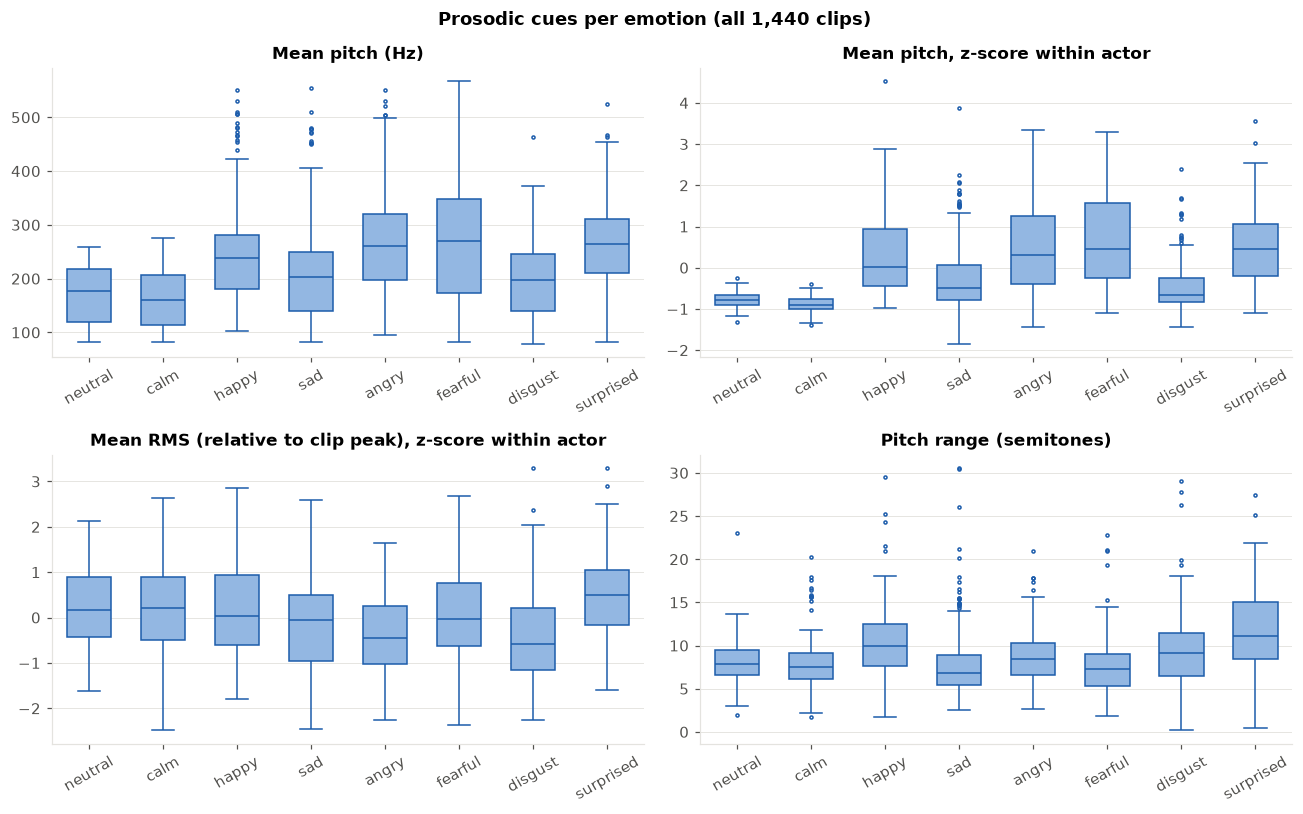

In [5]:
df = df.copy()
df["f0_z_actor"] = df.groupby("actor")["f0_mean"].transform(lambda s: (s - s.mean()) / s.std())
df["rms_z_actor"] = df.groupby("actor")["rms_mean"].transform(lambda s: (s - s.mean()) / s.std())

panels = [("f0_mean", "Mean pitch (Hz)"), ("f0_z_actor", "Mean pitch, z-score within actor"),
          ("rms_z_actor", "Mean RMS (relative to clip peak), z-score within actor"), ("f0_range", "Pitch range (semitones)")]
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (col, label) in zip(axes.flat, panels):
    sns.boxplot(data=df, x="emotion", y=col, order=EMOTION_ORDER, ax=ax, color="#86b6ef",
                width=0.6, fliersize=2, linewidth=1, linecolor="#1c5cab")
    ax.set_title(label)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Prosodic cues per emotion (all 1,440 clips)", fontweight="bold")
fig.tight_layout()
save(fig, "05_prosody_by_emotion")
plt.show()

## 4. How much do the 190 features overlap?
The heat map shows blocks of related features, for example spectral contrast with tonnetz and chroma, and MFCC means with their Δ statistics. Strong one-to-one duplicates are rare, though. The bigger problem for a classifier is **irrelevance**: with 190 features and only about 1,200 training clips per fold, features that carry little emotion information add noise and raise the risk of overfitting. Feature selection tackles both redundancy and irrelevance.

Feature pairs with |r| > 0.5: 735 of 17955 (4.1%)
Feature pairs with |r| > 0.7: 184 of 17955 (1.0%)
Feature pairs with |r| > 0.8: 56 of 17955 (0.3%)


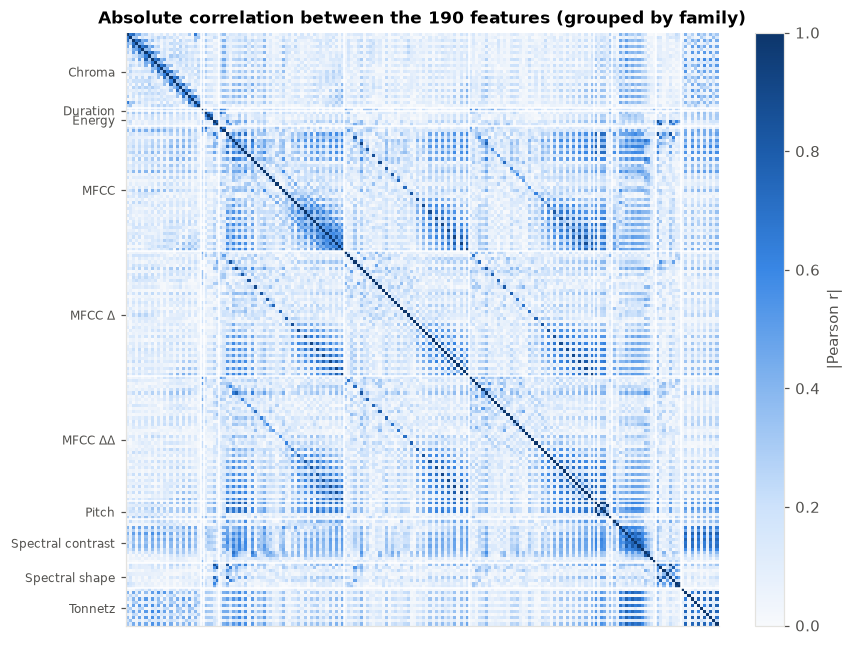

In [6]:
X_std = StandardScaler().fit_transform(df[FEATURE_COLS])
corr = np.corrcoef(X_std, rowvar=False)
upper = np.abs(corr[np.triu_indices_from(corr, k=1)])
for t in (0.5, 0.7, 0.8):
    print(f"Feature pairs with |r| > {t}: {(upper > t).sum()} of {upper.size} ({100 * (upper > t).mean():.1f}%)")

order = np.argsort(groups.values, kind="stable")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(np.abs(corr[np.ix_(order, order)]), cmap=SEQ_CMAP, vmin=0, vmax=1)
ax.grid(False)
# mark family boundaries
fam = groups.values[order]
bounds = [i for i in range(1, len(fam)) if fam[i] != fam[i - 1]]
for b in bounds:
    ax.axhline(b - 0.5, color="white", lw=1)
    ax.axvline(b - 0.5, color="white", lw=1)
starts = [0] + bounds
ends = bounds + [len(fam)]
ax.set_yticks([(s + e) / 2 for s, e in zip(starts, ends)])
ax.set_yticklabels([fam[s] for s in starts], fontsize=8)
ax.set_xticks([])
fig.colorbar(im, ax=ax, fraction=0.046, label="|Pearson r|")
ax.set_title("Absolute correlation between the 190 features (grouped by family)")
save(fig, "07_feature_correlation")
plt.show()

## 5. A 2-D picture of the feature space
t-SNE squeezes the 190-D space into 2-D. Each panel highlights one emotion in colour against all other clips in grey. Small multiples are clearer than eight overlapping colours.

What the map shows: low-arousal emotions (calm, neutral) gather in compact regions, while high-arousal emotions (happy, fearful, angry) are spread widely. Most emotions appear in **two separate groups**, and the next plot explains why.

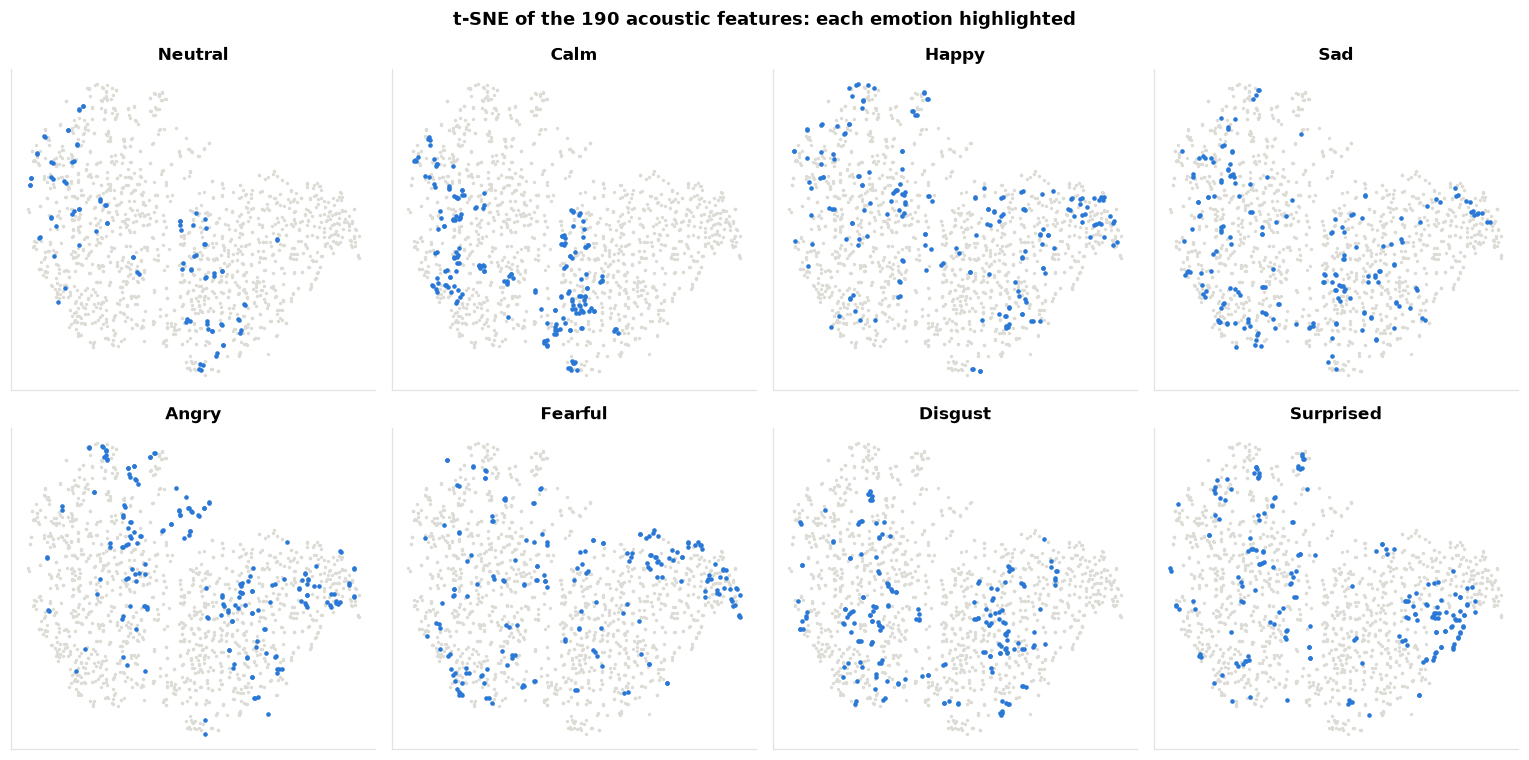

In [7]:
emb = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE, init="pca").fit_transform(X_std)
fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True)
for ax, emo in zip(axes.flat, EMOTION_ORDER):
    mask = (df["emotion"] == emo).to_numpy()
    ax.scatter(emb[~mask, 0], emb[~mask, 1], s=5, color="#dcdbd6", linewidths=0)
    ax.scatter(emb[mask, 0], emb[mask, 1], s=9, color="#2a78d6", linewidths=0)
    ax.set_title(emo.capitalize())
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("t-SNE of the 190 acoustic features: each emotion highlighted", fontweight="bold")
fig.tight_layout()
save(fig, "06_tsne_by_emotion")
plt.show()

**Same view, split by actor gender.** The two groups are male and female voices, almost without overlap. **The strongest structure in the raw features is the speaker, not the emotion.** A random train/test split would let a model "cheat" by recognising voices it has already heard. That is why every experiment in this project holds out whole actors.

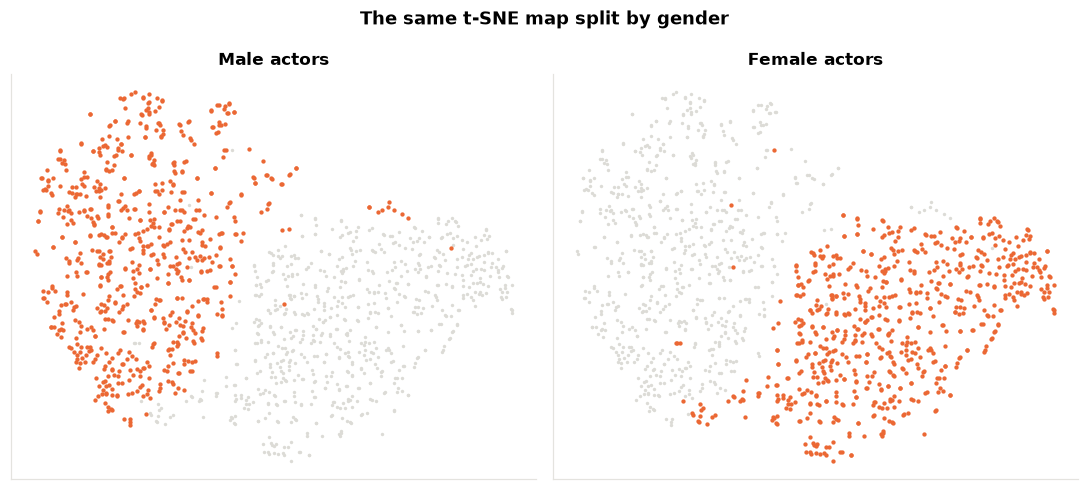

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, g in zip(axes, ["male", "female"]):
    mask = (df["gender"] == g).to_numpy()
    ax.scatter(emb[~mask, 0], emb[~mask, 1], s=5, color="#dcdbd6", linewidths=0)
    ax.scatter(emb[mask, 0], emb[mask, 1], s=8, color="#eb6834", linewidths=0)
    ax.set_title(f"{g.capitalize()} actors")
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("The same t-SNE map split by gender", fontweight="bold")
fig.tight_layout()
save(fig, "06b_tsne_by_gender")
plt.show()

## Summary
- 1,440 clips × 190 features, no missing values, saved to `data/features.csv` (this file is our **dataset submission**).
- Once each speaker's own baseline is removed, pitch is clearly higher for high-arousal emotions (happy, angry, fearful, surprised) than for neutral, calm, sad and disgust.
- In the raw feature space, gender and speaker dominate the structure, which justifies speaker-independent testing.
- The feature set contains related blocks and many weakly informative features, so selecting a smaller subset should help. That is what Solutions 1–3 do.